# 03 - RUL Target Engineering & Data Preprocessing
## NASA C-MAPSS Turbofan Degradation Simulation (FD001)

### Learning Objectives
1. **RUL Target Formulation**: Calculate Remaining Useful Life (RUL) from run-to-failure trajectories.
2. **Defensive Validation**: Programmatically verify that every training engine terminates precisely at $RUL = 0$.
3. **Target Analysis**: Inspect RUL distributions and individual engine linear degradation curves.
4. **Data Preprocessing & Auditing**:
   - Check missing values and duplicate rows.
   - Detect zero/near-zero variance telemetry channels ($\sigma^2 < 10^{-5}$).
   - Remove uninformative sensors with documented engineering justifications.
5. **Leak-Free Separation**:
   - Separate predictive features $X$, target $y$ ($RUL$), and engine identifier (`unit_number`).
   - Ensure $RUL$ is never used as an input feature.
   - Ensure `unit_number` is isolated for group-based validation.

*Note: No data scaling is applied yet, and no ML models are trained.*

In [1]:
import sys
from pathlib import Path

# Setup project root
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_loader import load_train_data
from src.preprocessing import (
    create_rul_target,
    check_missing_values,
    check_duplicates,
    identify_low_variance_features,
    select_informative_features,
    separate_features_target,
    get_feature_removal_reasons
)

# Plot styling configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.autolayout'] = False

FIGURES_DIR = project_root / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Load raw training data
raw_train = load_train_data(data_dir=project_root / "data" / "raw")
print(f"Loaded Raw Training Data: {raw_train.shape[0]:,} rows x {raw_train.shape[1]} columns.")

Loaded Raw Training Data: 20,631 rows x 26 columns.


---
## 1. RUL Target Engineering

In the C-MAPSS training trajectories, each engine operates until catastrophic functional failure.
For an engine $i$ whose final operational cycle is $T_i = \max(\text{time\_cycles}_i)$, the Remaining Useful Life at any cycle $t$ is formulated as:

$$RUL_{i, t} = T_i - t$$

At cycle $t = T_i$, the asset reaches end-of-life, yielding $RUL_{i, T_i} = 0$.

We invoke `create_rul_target()` from `src/preprocessing.py`. This function:
- Computes $RUL$ grouped by `unit_number`.
- Does not modify the input DataFrame in-place.
- Enforces an automated assertion that the final cycle of every engine satisfies $RUL = 0$.

In [2]:
train_with_rul = create_rul_target(raw_train, validate_zero_end=True)
print(f"RUL Target Created! DataFrame shape: {train_with_rul.shape}")
print(f"Target column 'RUL' successfully added: {'RUL' in train_with_rul.columns}")
print(f"Raw DataFrame left unmodified: {'RUL' not in raw_train.columns}")

RUL Target Created! DataFrame shape: (20631, 27)
Target column 'RUL' successfully added: True
Raw DataFrame left unmodified: True


### Inspecting Engine #1 Trajectory Examples
Let us examine the first 5 and last 5 operating cycles of Engine #1 to observe the monotonic decline of RUL toward failure.

In [3]:
engine_1_data = train_with_rul[train_with_rul['unit_number'] == 1]
max_c1 = engine_1_data['time_cycles'].max()

print(f"=== ENGINE #1 TRAJECTORY (Total Lifetime: {max_c1} cycles) ===")
print("\nFirst 5 Cycles (Healthy Stage):")
display(engine_1_data[['unit_number', 'time_cycles', 'operational_setting_1', 'sensor_2', 'sensor_3', 'RUL']].head()) if 'display' in globals() else print(engine_1_data[['unit_number', 'time_cycles', 'sensor_2', 'sensor_3', 'RUL']].head())

print("\nLast 5 Cycles (Terminal Degradation to Failure):")
display(engine_1_data[['unit_number', 'time_cycles', 'operational_setting_1', 'sensor_2', 'sensor_3', 'RUL']].tail()) if 'display' in globals() else print(engine_1_data[['unit_number', 'time_cycles', 'sensor_2', 'sensor_3', 'RUL']].tail())

=== ENGINE #1 TRAJECTORY (Total Lifetime: 192 cycles) ===

First 5 Cycles (Healthy Stage):
   unit_number  time_cycles  sensor_2  sensor_3  RUL
0            1            1    641.82   1589.70  191
1            1            2    642.15   1591.82  190
2            1            3    642.35   1587.99  189
3            1            4    642.35   1582.79  188
4            1            5    642.37   1582.85  187

Last 5 Cycles (Terminal Degradation to Failure):
     unit_number  time_cycles  sensor_2  sensor_3  RUL
187            1          188    643.75   1602.38    4
188            1          189    644.18   1596.17    3
189            1          190    643.64   1599.22    2
190            1          191    643.34   1602.36    1
191            1          192    643.54   1601.41    0


### Rigorous End-of-Life Verification
We explicitly test and verify that every engine in the training set reaches $RUL = 0$ on its final recorded cycle.

In [4]:
final_rul_per_unit = train_with_rul.groupby('unit_number')['RUL'].last()

print("=" * 60)
print("             FINAL CYCLE RUL VERIFICATION")
print("=" * 60)
print(f"Total Engines Evaluated     : {len(final_rul_per_unit)}")
print(f"Engines Ending at RUL == 0 : {(final_rul_per_unit == 0).sum()}")
print(f"Minimum Terminal RUL        : {final_rul_per_unit.min()}")
print(f"Maximum Terminal RUL        : {final_rul_per_unit.max()}")

assert (final_rul_per_unit == 0).all(), "CRITICAL ERROR: Found engine not ending at RUL = 0!"
print("\nSUCCESS: 100% of training engines verified to end at RUL = 0.")

             FINAL CYCLE RUL VERIFICATION
Total Engines Evaluated     : 100
Engines Ending at RUL == 0 : 100
Minimum Terminal RUL        : 0
Maximum Terminal RUL        : 0

SUCCESS: 100% of training engines verified to end at RUL = 0.


---
## 2. Visualizing RUL Distributions and Degradation Trajectories

Let us visualize the global distribution of RUL across all 20,631 records, followed by individual engine linear decline profiles.

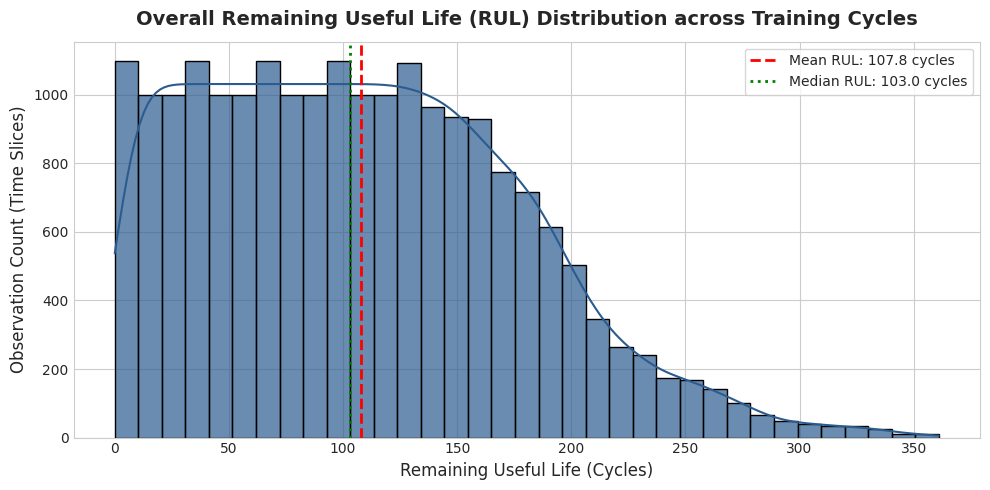

In [5]:
# Plot: RUL Distribution
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(train_with_rul['RUL'], kde=True, bins=35, color='#2b5c8f', ax=ax, edgecolor='black', alpha=0.7)
ax.axvline(train_with_rul['RUL'].mean(), color='red', linestyle='--', linewidth=2, 
           label=f"Mean RUL: {train_with_rul['RUL'].mean():.1f} cycles")
ax.axvline(train_with_rul['RUL'].median(), color='green', linestyle=':', linewidth=2, 
           label=f"Median RUL: {train_with_rul['RUL'].median():.1f} cycles")
ax.set_title('Overall Remaining Useful Life (RUL) Distribution across Training Cycles', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Remaining Useful Life (Cycles)', fontsize=12)
ax.set_ylabel('Observation Count (Time Slices)', fontsize=12)
ax.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '07_rul_distribution.png', dpi=300)
plt.show()

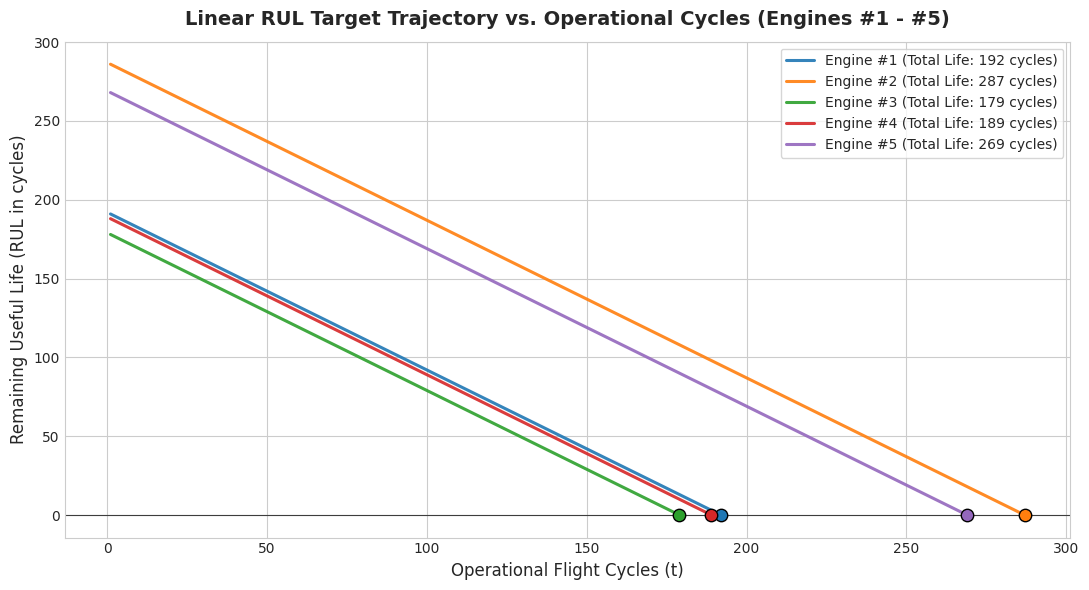

In [6]:
# Plot: Linear RUL Trajectories for Selected Engines
fig, ax = plt.subplots(figsize=(11, 6))
sample_units = [1, 2, 3, 4, 5]
palette = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

for unit, color in zip(sample_units, palette):
    engine_data = train_with_rul[train_with_rul['unit_number'] == unit]
    ax.plot(engine_data['time_cycles'], engine_data['RUL'], 
            label=f"Engine #{unit} (Total Life: {engine_data['time_cycles'].max()} cycles)", 
            color=color, linewidth=2.2, alpha=0.9)
    ax.scatter(engine_data['time_cycles'].max(), 0, color=color, s=80, zorder=5, edgecolors='black')

ax.set_title('Linear RUL Target Trajectory vs. Operational Cycles (Engines #1 - #5)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Operational Flight Cycles (t)', fontsize=12)
ax.set_ylabel('Remaining Useful Life (RUL in cycles)', fontsize=12)
ax.axhline(0, color='black', linestyle='-', linewidth=0.8, alpha=0.7)
ax.legend(loc='upper right', frameon=True, fontsize=10)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '08_rul_vs_cycles.png', dpi=300)
plt.show()

---
## 3. Data Integrity Audits (Missing Values & Duplicates)

We audit data quality before feature selection.

In [7]:
missing_series = check_missing_values(train_with_rul)
duplicate_rows = check_duplicates(train_with_rul)
duplicate_keys = check_duplicates(train_with_rul, subset=['unit_number', 'time_cycles'])

print("=== DATA INTEGRITY AUDIT ===")
print(f"Total Missing Values Across All Columns : {missing_series.sum()}")
print(f"Total Duplicate Rows                    : {duplicate_rows}")
print(f"Duplicate (unit_number, cycle) Keys    : {duplicate_keys}")

=== DATA INTEGRITY AUDIT ===
Total Missing Values Across All Columns : 0
Total Duplicate Rows                    : 0
Duplicate (unit_number, cycle) Keys    : 0


---
## 4. Variance Analysis & Feature Selection

Based on our EDA findings, features with zero or near-zero variance ($\sigma^2 < 10^{-5}$) carry zero predictive entropy and should be pruned to prevent ill-conditioned covariance matrices and unnecessary model complexity.

### Technical & Physical Justifications for Feature Removal:

In [8]:
reasons = get_feature_removal_reasons()
justification_df = pd.DataFrame([
    {"Feature": feat, "Justification & Physical Mechanism": reason}
    for feat, reason in reasons.items()
])
pd.set_option('display.max_colwidth', None)
justification_df

,Feature,Justification & Physical Mechanism
0,sensor_1,Fan inlet temperature (T2): Constant at 518.67 °R (variance = 0.000000). Represents fixed ambient sea-level inlet condition; provides zero degradation signal.
1,sensor_5,Fan inlet pressure (P2): Constant at 14.62 psia (variance = 0.000000). Ambient sea-level pressure condition; completely static.
2,sensor_6,"Bypass-duct static pressure (P15): Negligible variance (2.0e-6), fluctuating only between 21.60 and 21.61 psia. Insufficient variation to track engine wear."
3,sensor_10,Engine pressure ratio (P50/P2): Constant at 1.30 (variance = 0.000000). Does not vary across operational cycles in single-operating-condition subset FD001.
4,sensor_16,Burner fuel-air ratio (dAmb): Constant at 0.03 (variance = 0.000000). Static combustion chamber parameter; invariant to component degradation.
5,sensor_18,"Demanded fan speed (Nf_dmd): Constant at 2388.0 rpm (variance = 0.000000). Commanded setpoint from digital electronic engine control (FADEC), not an output sensor."
6,sensor_19,Demanded corrected fan speed (PCNfR_dmd): Constant at 100.0 rpm (variance = 0.000000). Nominal control setpoint; completely invariant across all engines.
7,operational_setting_3,Flight condition setting 3: Constant at 100.0 (variance = 0.000000). FD001 simulates a single sea-level operating regime; this setting is stationary.


### Executing Feature Selection
We invoke `select_informative_features()` to retain informative sensors and operating time while cleanly dropping static channels.

In [9]:
initial_feature_count = raw_train.shape[1]

processed_df, selected_features, removed_features = select_informative_features(
    train_with_rul,
    variance_threshold=1e-5,
    include_operational_settings=False,  # Settings in FD001 have negligible noise variance
    include_time_cycles=True
)

print("=" * 70)
print("                   FEATURE SELECTION SUMMARY")
print("=" * 70)
print(f"Initial Feature Count (Raw Telemetry) : {initial_feature_count}")
print(f"Removed Uninformative Channels        : {len(removed_features)}")
print(f"Final Retained Feature Count          : {len(selected_features)}")
print("-" * 70)
print("Removed Features:")
for f in removed_features:
    print(f"  - {f}")
print("\nFinal Selected Predictive Features:")
for f in selected_features:
    print(f"  + {f}")

                   FEATURE SELECTION SUMMARY
Initial Feature Count (Raw Telemetry) : 26
Removed Uninformative Channels        : 10
Final Retained Feature Count          : 15
----------------------------------------------------------------------
Removed Features:
  - sensor_1
  - sensor_10
  - sensor_19
  - sensor_18
  - sensor_16
  - sensor_5
  - sensor_6
  - operational_setting_3
  - operational_setting_2
  - operational_setting_1

Final Selected Predictive Features:
  + time_cycles
  + sensor_15
  + sensor_8
  + sensor_13
  + sensor_21
  + sensor_20
  + sensor_11
  + sensor_2
  + sensor_12
  + sensor_7
  + sensor_17
  + sensor_3
  + sensor_4
  + sensor_14
  + sensor_9


---
## 5. Feature Matrix and Target Separation ($X, y, \text{unit\_ids}$)

To adhere strictly to ML engineering principles:
1. **$X$ (Feature Matrix)**: Contains only the 15 selected informative features.
2. **$y$ (Target Vector)**: Contains the continuous $RUL$ target.
3. **`unit_ids` (Grouping Vector)**: Contains `unit_number` stored separately for GroupKFold / engine-based partitioning.
4. **Data Leakage Check**: Confirmed that $RUL$ and `unit_number` are never present in $X$.

In [10]:
X, y, unit_ids = separate_features_target(
    processed_df,
    feature_cols=selected_features,
    target_col='RUL',
    id_col='unit_number'
)

print("=== FINAL DATASET PARTITION ===")
print(f"X (Features Matrix) : Shape {X.shape} (Records: {X.shape[0]:,}, Features: {X.shape[1]})")
print(f"y (Target Vector)   : Shape {y.shape} (Values: {len(y):,})")
print(f"unit_ids (Grouping) : Shape {unit_ids.shape} ({unit_ids.nunique()} unique engines)")

# Defensive Assertions
assert 'RUL' not in X.columns, "Leakage Error: RUL target found in feature matrix X!"
assert 'unit_number' not in X.columns, "Leakage Error: unit_number found in feature matrix X!"
assert len(X) == len(y) == len(unit_ids), "Alignment Error: Inconsistent row dimensions!"
print("\nAll defensive assertions passed successfully!")

=== FINAL DATASET PARTITION ===
X (Features Matrix) : Shape (20631, 15) (Records: 20,631, Features: 15)
y (Target Vector)   : Shape (20631,) (Values: 20,631)
unit_ids (Grouping) : Shape (20631,) (100 unique engines)

All defensive assertions passed successfully!


---
## 6. Preprocessing Summary Table

| Metric / Step | Value | ML Context |
| :--- | :--- | :--- |
| **Initial Raw Columns** | 26 columns | Telemetry, settings, and indices |
| **RUL Computed** | Yes ($T_i - t$) | Target variable engineered; 100% verified to hit 0 at failure |
| **Removed Features** | 10 columns (`sensor_1, 5, 6, 10, 16, 18, 19`, `setting_1, 2, 3`) | Zero or near-zero variance; zero degradation information |
| **Retained ML Features** | 15 features (`time_cycles` + 14 informative sensors) | Sufficient variance, high physical sensitivity to wear |
| **Engine ID Handling** | Isolated in `unit_ids` | Required for group-aware train/val cross-validation |
| **Scaling Status** | Not applied yet | Scaler will be fit strictly on train split in Step 5 |

*Next Step: Proceed to `04_feature_engineering.ipynb` to develop causal rolling window statistics (rolling mean, rolling std) and piecewise RUL clipping.*